# Analyzing ClinVar variants

In [3]:
import os
import polars as pl
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
# import concurrent.futures

aa_single_to_three = {
    'A': 'Ala',  # Alanine
    'R': 'Arg',  # Arginine
    'N': 'Asn',  # Asparagine
    'D': 'Asp',  # Aspartic acid
    'C': 'Cys',  # Cysteine
    'Q': 'Gln',  # Glutamine
    'E': 'Glu',  # Glutamic acid
    'G': 'Gly',  # Glycine
    'H': 'His',  # Histidine
    'I': 'Ile',  # Isoleucine
    'L': 'Leu',  # Leucine
    'K': 'Lys',  # Lysine
    'M': 'Met',  # Methionine
    'F': 'Phe',  # Phenylalanine
    'P': 'Pro',  # Proline
    'S': 'Ser',  # Serine
    'T': 'Thr',  # Threonine
    'W': 'Trp',  # Tryptophan
    'Y': 'Tyr',  # Tyrosine
    'V': 'Val'   # Valine
}

## Loading the dbnsfp snps

In [3]:
# df_clinvar_dup = pl.scan_parquet(f"../3_outputs/processed_data/dbnsfp/dbNSFP5.0a_variant.clin_var_re-annot.parquet")
# df_clinvar_dup.collect()

In [4]:
df_clinvar = pl.scan_parquet(f"../3_outputs/processed_data/dbnsfp/dbNSFP5.0a_variant.clin_var_re-annot_pdb_variants.parquet")
df_clinvar.collect()
# df_clinvar.filter(pl.col("aaalt").str.len_chars() == 1).collect()

clinvar_id,#chr,pos(1-based),ref,alt,aaref,aaalt,rs_dbSNP,hg19_chr,hg19_pos(1-based),hg18_chr,hg18_pos(1-based),aapos,genename,Ensembl_geneid,Ensembl_transcriptid,Ensembl_proteinid,Uniprot_acc,Uniprot_entry,HGVSc_snpEff,HGVSp_snpEff,HGVSc_VEP,HGVSp_VEP,APPRIS,GENCODE_basic,TSL,VEP_canonical,MANE,cds_strand,refcodon,codonpos,codon_degeneracy,Ancestral_allele,AltaiNeandertal,Denisova,VindijiaNeandertal,ChagyrskayaNeandertal,…,nsv/esv (dbVar),RCVaccession,PhenotypeIDS,PhenotypeList,Origin,OriginSimple,Assembly,ChromosomeAccession,Chromosome,Start,Stop,Cytogenetic,ReviewStatus,NumberSubmitters,Guidelines,TestedInGTR,OtherIDs,SubmitterCategories,VariationID,PositionVCF,ReferenceAlleleVCF,AlternateAlleleVCF,SomaticClinicalImpact,SomaticClinicalImpactLastEvaluated,ReviewStatusClinicalImpact,Oncogenicity,OncogenicityLastEvaluated,ReviewStatusOncogenicity,SCVsForAggregateGermlineClassification,SCVsForAggregateSomaticClinicalImpact,SCVsForAggregateOncogenicityClassification,clinvar_nt_change,clinvar_aa_change,SPDI,RefSeq_mRNA,StarStatus,clinvar_clnsig_clean
str,str,i64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,…,str,str,str,str,str,str,cat,str,str,i64,i64,str,cat,i64,str,str,str,i64,i64,i64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,i32,cat
"""2361281""","""21""",13628442,"""G""","""T""","""S""","""I""","""rs905107791""","""21""","""15000763""","""21""","""13922634""","""396""","""POTED""","""ENSG00000166351""","""ENST00000299443""","""ENSP00000299443""","""Q86YR6""","""POTED_HUMAN""","""c.1187G>T""","""p.Ser396Ile""","""c.1187G>T""","""p.Ser396Ile""","""principal1""","""Y""","""1""","""YES""","""Select""","""+""","""AGC""","""2""","""0""",""".""","""./.""","""./.""","""./.""","""./.""",…,"""-""","""RCV004201236""","""MedGen:CN169374""","""not specified""","""germline""","""germline""","""GRCh38""","""NC_000021.9""","""21""",13628442,13628442,"""21q11.2""","""criteria provided, single subm…",1,"""-""","""N""","""ClinGen:CA317768197""",2,2361281,13628442,"""G""","""T""","""-""","""-""","""-""","""-""","""-""","""-""","""SCV003702401""","""-""","""-""","""1187G>T ""","""Ser396Ile""","""NC_000021.9:13628442:G:T""","""NM_174981.6""",1,"""4_VUS"""
"""2599176""","""21""",13630941,"""G""","""T""","""V""","""F""","""rs937658823""","""21""","""15003262""","""21""","""13925133""","""415""","""POTED""","""ENSG00000166351""","""ENST00000299443""","""ENSP00000299443""","""Q86YR6""","""POTED_HUMAN""","""c.1243G>T""","""p.Val415Phe""","""c.1243G>T""","""p.Val415Phe""","""principal1""","""Y""","""1""","""YES""","""Select""","""+""","""GTT""","""1""","""0""",""".""","""./.""","""./.""","""./.""","""./.""",…,"""-""","""RCV004345528""","""MedGen:CN169374""","""not specified""","""germline""","""germline""","""GRCh38""","""NC_000021.9""","""21""",13630941,13630941,"""21q11.2""","""criteria provided, single subm…",1,"""-""","""N""","""ClinGen:CA317768279""",2,2599176,13630941,"""G""","""T""","""-""","""-""","""-""","""-""","""-""","""-""","""SCV004065319""","""-""","""-""","""1243G>T ""","""Val415Phe""","""NC_000021.9:13630941:G:T""","""NM_174981.6""",1,"""4_VUS"""
"""2486768""","""21""",13630977,"""G""","""A""","""V""","""M""",""".""","""21""","""15003298""","""21""","""13925169""","""427""","""POTED""","""ENSG00000166351""","""ENST00000299443""","""ENSP00000299443""","""Q86YR6""","""POTED_HUMAN""","""c.1279G>A""","""p.Val427Met""","""c.1279G>A""","""p.Val427Met""","""principal1""","""Y""","""1""","""YES""","""Select""","""+""","""GTG""","""1""","""0""",""".""","""./.""","""./.""","""./.""","""./.""",…,"""-""","""RCV004275341""","""MedGen:CN169374""","""not specified""","""germline""","""germline""","""GRCh38""","""NC_000021.9""","""21""",13630977,13630977,"""21q11.2""","""criteria provided, single subm…",1,"""-""","""N""","""ClinGen:CA409859409""",2,2486768,13630977,"""G""","""A""","""-""","""-""","""-""","""-""","""-""","""-""","""SCV003905383""

In [5]:
# Once you’re happy with the behavior on the subset,
# you can apply it to the entire lazy DataFrame.
# Assume ldf is your lazy DataFrame.
# Randomly sample 1000 rows from the exploded DataFrame
# df_clinvar_sampled = df_clinvar_exploded.collect().sample(n=1000)

variant_annot = [
    "hg19_chr","genename","Ensembl_geneid","Ensembl_proteinid",
    "Uniprot_acc","Uniprot_entry",
    "aapos","aaref","aaref_3","aaalt","aaalt_3",#"aa_change",
    "Ensembl_transcriptid","hg19_pos(1-based)","HGVSc_snpEff","HGVSp_snpEff",
    "HGVSc_VEP","HGVSp_VEP",
]
predictor_algos = [
    "PROVEAN_score","PROVEAN_converted_rankscore","PROVEAN_pred",
    "ESM1b_score","ESM1b_rankscore","ESM1b_pred",
    "AlphaMissense_score","AlphaMissense_rankscore","AlphaMissense_pred"
] + [col for col in df_clinvar.collect_schema().names() if "clinvar" in col]

## AI-predictor scores distribution

In [5]:
df_clinvar_sampled_plots = df_clinvar.select(
    pl.col("ESM1b_score","AlphaMissense_score","PROVEAN_score","clinvar_clnsig_clean")
).with_columns(
    pl.col("ESM1b_score").replace(".", None).cast(pl.Float64).alias("esm1b"),
    pl.col("AlphaMissense_score").replace(".", None).cast(pl.Float64).alias("alphamissense"),
    pl.col("PROVEAN_score").replace(".", None).cast(pl.Float64).alias("provean")
).filter((pl.col("clinvar_clnsig_clean")!="4_VUS")&(pl.col("clinvar_clnsig_clean")!="5_Others")).collect()

df_clinvar_sampled_plots

ESM1b_score,AlphaMissense_score,PROVEAN_score,clinvar_clnsig_clean,esm1b,alphamissense,provean
str,str,str,cat,f64,f64,f64
"""-5.093""","""0.12""","""-0.28""","""2_Benign""",-5.093,0.12,-0.28
""".""",""".""",""".""","""2_Benign""",null,null,null
"""-6.57""","""0.059""","""0.67""","""2_Benign""",-6.57,0.059,0.67
"""-1.991""","""0.0597""","""0.98""","""2_Benign""",-1.991,0.0597,0.98
"""-3.62""","""0.0714""","""-0.25""","""2_Benign""",-3.62,0.0714,-0.25
…,…,…,…,…,…,…
"""-9.584""","""0.1812""","""-3.61""","""3_Conflicting""",-9.584,0.1812,-3.61
"""-5.134""",""".""",""".""","""2_Benign""",-5.134,null,null
"""-5.814""","""0.6774""","""-1.93""","""1_Pathogenic""",-5.814,0.6774,-1.93


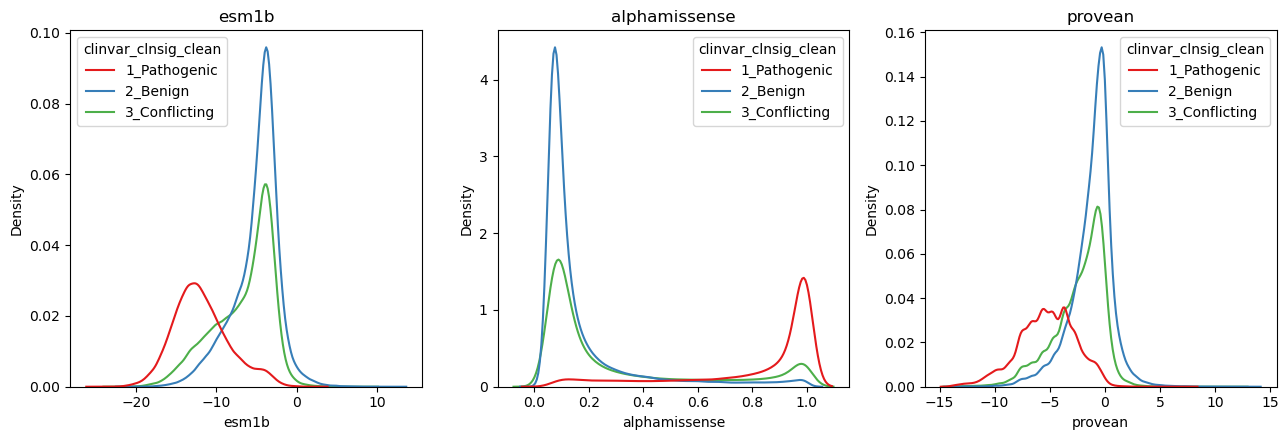

In [6]:
# Define variables to plot
variables = ["esm1b", "alphamissense", "provean"]

# Create a FacetGrid for multiple subplots
fig, axes = plt.subplots(1, 3, figsize=(13, 4.5)) ## , sharey=True
hue_order = sorted(df_clinvar_sampled_plots["clinvar_clnsig_clean"].drop_nulls().unique().to_list())
# Loop through variables and create subplots
for ax, var in zip(axes, variables):
    sns.kdeplot(
        data=df_clinvar_sampled_plots,
        x=var,
        hue="clinvar_clnsig_clean",
        hue_order=hue_order,
        # kde=True,
        ax=ax,
        palette="Set1"
    )
    ax.set_title(var)
    
plt.tight_layout()
plt.show()

## AI-predictor scores across structure

In [6]:
df_clinvar_scores = pl.scan_parquet(f"../3_outputs/processed_data/dbnsfp/dbNSFP5.0a_variant.clin_var_re-annot_pdb_variants_plddt_rsa.parquet")
df_clinvar_scores = df_clinvar_scores.with_columns(
    pl.col("plddt").cast(pl.Float32).alias("plddt_f32"),
    pl.col("rsa").cast(pl.Float32).alias("rsa_f32"),
)
# df_clinvar_scores.collect()

In [7]:
df_clinvar_scores.filter(~pl.col("plddt_f32").is_nan()).collect()

clinvar_id,#chr,pos(1-based),ref,alt,aaref,aaalt,rs_dbSNP,hg19_chr,hg19_pos(1-based),hg18_chr,hg18_pos(1-based),aapos,genename,Ensembl_geneid,Ensembl_transcriptid,Ensembl_proteinid,Uniprot_acc,Uniprot_entry,HGVSc_snpEff,HGVSp_snpEff,HGVSc_VEP,HGVSp_VEP,APPRIS,GENCODE_basic,TSL,VEP_canonical,MANE,cds_strand,refcodon,codonpos,codon_degeneracy,Ancestral_allele,AltaiNeandertal,Denisova,VindijiaNeandertal,ChagyrskayaNeandertal,…,Origin,OriginSimple,Assembly,ChromosomeAccession,Chromosome,Start,Stop,Cytogenetic,ReviewStatus,NumberSubmitters,Guidelines,TestedInGTR,OtherIDs,SubmitterCategories,VariationID,PositionVCF,ReferenceAlleleVCF,AlternateAlleleVCF,SomaticClinicalImpact,SomaticClinicalImpactLastEvaluated,ReviewStatusClinicalImpact,Oncogenicity,OncogenicityLastEvaluated,ReviewStatusOncogenicity,SCVsForAggregateGermlineClassification,SCVsForAggregateSomaticClinicalImpact,SCVsForAggregateOncogenicityClassification,clinvar_nt_change,clinvar_aa_change,SPDI,RefSeq_mRNA,StarStatus,clinvar_clnsig_clean,plddt,rsa,plddt_f32,rsa_f32
str,str,i64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,…,str,str,cat,str,str,i64,i64,str,cat,i64,str,str,str,i64,i64,i64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,i32,cat,f64,f64,f32,f32
"""2361281""","""21""",13628442,"""G""","""T""","""S""","""I""","""rs905107791""","""21""","""15000763""","""21""","""13922634""","""396""","""POTED""","""ENSG00000166351""","""ENST00000299443""","""ENSP00000299443""","""Q86YR6""","""POTED_HUMAN""","""c.1187G>T""","""p.Ser396Ile""","""c.1187G>T""","""p.Ser396Ile""","""principal1""","""Y""","""1""","""YES""","""Select""","""+""","""AGC""","""2""","""0""",""".""","""./.""","""./.""","""./.""","""./.""",…,"""germline""","""germline""","""GRCh38""","""NC_000021.9""","""21""",13628442,13628442,"""21q11.2""","""criteria provided, single subm…",1,"""-""","""N""","""ClinGen:CA317768197""",2,2361281,13628442,"""G""","""T""","""-""","""-""","""-""","""-""","""-""","""-""","""SCV003702401""","""-""","""-""","""1187G>T ""","""Ser396Ile""","""NC_000021.9:13628442:G:T""","""NM_174981.6""",1,"""4_VUS""",32.34,0.953846,32.34,0.953846
"""2599176""","""21""",13630941,"""G""","""T""","""V""","""F""","""rs937658823""","""21""","""15003262""","""21""","""13925133""","""415""","""POTED""","""ENSG00000166351""","""ENST00000299443""","""ENSP00000299443""","""Q86YR6""","""POTED_HUMAN""","""c.1243G>T""","""p.Val415Phe""","""c.1243G>T""","""p.Val415Phe""","""principal1""","""Y""","""1""","""YES""","""Select""","""+""","""GTT""","""1""","""0""",""".""","""./.""","""./.""","""./.""","""./.""",…,"""germline""","""germline""","""GRCh38""","""NC_000021.9""","""21""",13630941,13630941,"""21q11.2""","""criteria provided, single subm…",1,"""-""","""N""","""ClinGen:CA317768279""",2,2599176,13630941,"""G""","""T""","""-""","""-""","""-""","""-""","""-""","""-""","""SCV004065319""","""-""","""-""","""1243G>T ""","""Val415Phe""","""NC_000021.9:13630941:G:T""","""NM_174981.6""",1,"""4_VUS""",58.03,0.06338,58.029999,0.06338
"""2486768""","""21""",13630977,"""G""","""A""","""V""","""M""",""".""","""21""","""15003298""","""21""","""13925169""","""427""","""POTED""","""ENSG00000166351""","""ENST00000299443""","""ENSP00000299443""","""Q86YR6""","""POTED_HUMAN""","""c.1279G>A""","""p.Val427Met""","""c.1279G>A""","""p.Val427Met""","""principal1""","""Y""","""1""","""YES""","""Select""","""+""","""GTG""","""1""","""0""",""".""","""./.""","""./.""","""./.""","""./.""",…,"""germline""","""germline""","""GRCh38""","""NC_000021.9""","""21""",13630977,13630977,"""21q11.2""","""criteria provided, single subm…",1,"""-""","""N""","""ClinGen:CA409859409""",2,2486768,13630977,"""G""","""A""","""-""","""-""","""-""","""-""","""-""","""-""","""SCV003905383""","""-""","""-""","""1279G>A ""","""Val427Met""","""NC_000021.9:13630977:G:A""","""NM_174981.6""",1,"""2_Benign""",32.9,0.978873,32.900002,0.978873
"""2277922""","""21""",13

In [11]:
df_clinvar_w_scores = df_clinvar_scores.filter(
    ~pl.col("plddt_f32").is_nan()
).with_columns(
    (
        pl.when(pl.col("rsa_f32")<.1)
        .then(pl.lit("<10"))
        .when(pl.col("rsa_f32")>=.9)
        .then(pl.lit("$\geqslant$90"))
        .otherwise(pl.lit("10-90"))
    ).alias("rsa_cat"),
    (
        pl.when(pl.col("plddt_f32")<=50)
        .then(pl.lit("<=50"))
        .when((pl.col("plddt_f32")>50)&(pl.col("plddt_f32")<=70))
        .then(pl.lit("50-70"))
        .when((pl.col("plddt_f32")>70)&(pl.col("plddt_f32")<=90))
        .then(pl.lit("70-90"))
        .otherwise(pl.lit(">90"))
    ).alias("plddt_cat"),
    (
        pl.when(pl.col("AlphaMissense_pred").str.contains("B"))
        .then(pl.lit("2_Benign"))
        .when(pl.col("AlphaMissense_pred").str.contains("P"))
        .then(pl.lit("1_Pathogenic"))
        .when(pl.col("AlphaMissense_pred").str.contains("A"))
        .then(pl.lit("3_Ambiguous"))
        .otherwise(pl.lit("."))
    ).alias("AM_pred"),
    (
        pl.when(pl.col("PROVEAN_pred").str.contains("D"))
        .then(pl.lit("1_Damaging"))
        .when(pl.col("PROVEAN_pred").str.contains("N"))
        .then(pl.lit("2_Neutral"))
        .otherwise(pl.lit("."))
    ).alias("Provean_pred"),
    (
        pl.when(pl.col("ESM1b_pred").str.contains("D"))
        .then(pl.lit("1_Deleterious"))
        .when(pl.col("ESM1b_pred").str.contains("T"))
        .then(pl.lit("2_Tolerated"))
        .otherwise(pl.lit("."))
    ).alias("ESM1b_pred")
)

In [15]:
df_clinvar_w_scores.filter((pl.col("AlphaMissense_pred")!=".")).collect()

clinvar_id,#chr,pos(1-based),ref,alt,aaref,aaalt,rs_dbSNP,hg19_chr,hg19_pos(1-based),hg18_chr,hg18_pos(1-based),aapos,genename,Ensembl_geneid,Ensembl_transcriptid,Ensembl_proteinid,Uniprot_acc,Uniprot_entry,HGVSc_snpEff,HGVSp_snpEff,HGVSc_VEP,HGVSp_VEP,APPRIS,GENCODE_basic,TSL,VEP_canonical,MANE,cds_strand,refcodon,codonpos,codon_degeneracy,Ancestral_allele,AltaiNeandertal,Denisova,VindijiaNeandertal,ChagyrskayaNeandertal,…,Chromosome,Start,Stop,Cytogenetic,ReviewStatus,NumberSubmitters,Guidelines,TestedInGTR,OtherIDs,SubmitterCategories,VariationID,PositionVCF,ReferenceAlleleVCF,AlternateAlleleVCF,SomaticClinicalImpact,SomaticClinicalImpactLastEvaluated,ReviewStatusClinicalImpact,Oncogenicity,OncogenicityLastEvaluated,ReviewStatusOncogenicity,SCVsForAggregateGermlineClassification,SCVsForAggregateSomaticClinicalImpact,SCVsForAggregateOncogenicityClassification,clinvar_nt_change,clinvar_aa_change,SPDI,RefSeq_mRNA,StarStatus,clinvar_clnsig_clean,plddt,rsa,plddt_f32,rsa_f32,rsa_cat,plddt_cat,AM_pred,Provean_pred
str,str,i64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,…,str,i64,i64,str,cat,i64,str,str,str,i64,i64,i64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,i32,cat,f64,f64,f32,f32,str,str,str,str
"""2361281""","""21""",13628442,"""G""","""T""","""S""","""I""","""rs905107791""","""21""","""15000763""","""21""","""13922634""","""396""","""POTED""","""ENSG00000166351""","""ENST00000299443""","""ENSP00000299443""","""Q86YR6""","""POTED_HUMAN""","""c.1187G>T""","""p.Ser396Ile""","""c.1187G>T""","""p.Ser396Ile""","""principal1""","""Y""","""1""","""YES""","""Select""","""+""","""AGC""","""2""","""0""",""".""","""./.""","""./.""","""./.""","""./.""",…,"""21""",13628442,13628442,"""21q11.2""","""criteria provided, single subm…",1,"""-""","""N""","""ClinGen:CA317768197""",2,2361281,13628442,"""G""","""T""","""-""","""-""","""-""","""-""","""-""","""-""","""SCV003702401""","""-""","""-""","""1187G>T ""","""Ser396Ile""","""NC_000021.9:13628442:G:T""","""NM_174981.6""",1,"""4_VUS""",32.34,0.953846,32.34,0.953846,"""$\geqslant$90""","""<=50""","""2_Benign""","""2_Neutral"""
"""2599176""","""21""",13630941,"""G""","""T""","""V""","""F""","""rs937658823""","""21""","""15003262""","""21""","""13925133""","""415""","""POTED""","""ENSG00000166351""","""ENST00000299443""","""ENSP00000299443""","""Q86YR6""","""POTED_HUMAN""","""c.1243G>T""","""p.Val415Phe""","""c.1243G>T""","""p.Val415Phe""","""principal1""","""Y""","""1""","""YES""","""Select""","""+""","""GTT""","""1""","""0""",""".""","""./.""","""./.""","""./.""","""./.""",…,"""21""",13630941,13630941,"""21q11.2""","""criteria provided, single subm…",1,"""-""","""N""","""ClinGen:CA317768279""",2,2599176,13630941,"""G""","""T""","""-""","""-""","""-""","""-""","""-""","""-""","""SCV004065319""","""-""","""-""","""1243G>T ""","""Val415Phe""","""NC_000021.9:13630941:G:T""","""NM_174981.6""",1,"""4_VUS""",58.03,0.06338,58.029999,0.06338,"""<10""","""50-70""","""2_Benign""","""2_Neutral"""
"""2486768""","""21""",13630977,"""G""","""A""","""V""","""M""",""".""","""21""","""15003298""","""21""","""13925169""","""427""","""POTED""","""ENSG00000166351""","""ENST00000299443""","""ENSP00000299443""","""Q86YR6""","""POTED_HUMAN""","""c.1279G>A""","""p.Val427Met""","""c.1279G>A""","""p.Val427Met""","""principal1""","""Y""","""1""","""YES""","""Select""","""+""","""GTG""","""1""","""0""",""".""","""./.""","""./.""","""./.""","""./.""",…,"""21""",13630977,13630977,"""21q11.2""","""criteria provided, single subm…",1,"""-""","""N""","""ClinGen:CA409859409""",2,2486768,13630977,"""G""","""A""","""-""","""-""","""-""","""-""","""-""","""-""","""SCV003905383""","""-""","""-""","""1279G>A ""","""Val427Met""","""NC_000021.9:13630977:G:A""","""NM_174981.6""",1,"""2_Benign""",32.9,0.978873,32.900002,0.978873,"""$\geqslant$90""","""<=50""","""2_Benign""","""2_Neutral"""
"""2277922""","""21""",13631057,"""A""","

In [12]:
df_clinvar_w_scores.filter((pl.col("clinvar_clnsig_clean")=="1_Pathogenic")).collect()

clinvar_id,#chr,pos(1-based),ref,alt,aaref,aaalt,rs_dbSNP,hg19_chr,hg19_pos(1-based),hg18_chr,hg18_pos(1-based),aapos,genename,Ensembl_geneid,Ensembl_transcriptid,Ensembl_proteinid,Uniprot_acc,Uniprot_entry,HGVSc_snpEff,HGVSp_snpEff,HGVSc_VEP,HGVSp_VEP,APPRIS,GENCODE_basic,TSL,VEP_canonical,MANE,cds_strand,refcodon,codonpos,codon_degeneracy,Ancestral_allele,AltaiNeandertal,Denisova,VindijiaNeandertal,ChagyrskayaNeandertal,…,Chromosome,Start,Stop,Cytogenetic,ReviewStatus,NumberSubmitters,Guidelines,TestedInGTR,OtherIDs,SubmitterCategories,VariationID,PositionVCF,ReferenceAlleleVCF,AlternateAlleleVCF,SomaticClinicalImpact,SomaticClinicalImpactLastEvaluated,ReviewStatusClinicalImpact,Oncogenicity,OncogenicityLastEvaluated,ReviewStatusOncogenicity,SCVsForAggregateGermlineClassification,SCVsForAggregateSomaticClinicalImpact,SCVsForAggregateOncogenicityClassification,clinvar_nt_change,clinvar_aa_change,SPDI,RefSeq_mRNA,StarStatus,clinvar_clnsig_clean,plddt,rsa,plddt_f32,rsa_f32,rsa_cat,plddt_cat,AM_pred,Provean_pred
str,str,i64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,…,str,i64,i64,str,cat,i64,str,str,str,i64,i64,i64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,i32,cat,f64,f64,f32,f32,str,str,str,str
"""2420761""","""21""",18275274,"""G""","""A""","""Q""","""X""","""rs780237847""","""21""","""19647591""","""21""","""18569462""","""943""","""TMPRSS15""","""ENSG00000154646""","""ENST00000284885""","""ENSP00000284885""","""P98073""","""ENTK_HUMAN""","""c.2827C>T""","""p.Gln943*""","""c.2827C>T""","""p.Gln943Ter""","""principal1""","""Y""","""1""","""YES""","""Select""","""-""","""CAG""","""1""","""0""","""G""","""G/G""","""G/G""","""G/G""","""G/G""",…,"""21""",18275274,18275274,"""21q21.1""","""criteria provided, single subm…",1,"""-""","""N""","""ClinGen:CA9983882""",2,2420761,18275274,"""G""","""A""","""-""","""-""","""-""","""-""","""-""","""-""","""SCV003789125""","""-""","""-""","""2827C>T ""","""Gln943Ter""","""NC_000021.9:18275274:G:A""","""NM_002772.3""",1,"""1_Pathogenic""",91.22,0.666667,91.220001,0.666667,"""10-90""",""">90""",""".""","""."""
"""2814681""","""21""",18275316,"""G""","""A""","""Q""","""X""","""rs1228690395""","""21""","""19647633""","""21""","""18569504""","""929""","""TMPRSS15""","""ENSG00000154646""","""ENST00000284885""","""ENSP00000284885""","""P98073""","""ENTK_HUMAN""","""c.2785C>T""","""p.Gln929*""","""c.2785C>T""","""p.Gln929Ter""","""principal1""","""Y""","""1""","""YES""","""Select""","""-""","""CAA""","""1""","""0""","""G""","""G/G""","""G/G""","""G/G""","""G/G""",…,"""21""",18275316,18275316,"""21q21.1""","""criteria provided, single subm…",1,"""-""","""N""","""ClinGen:CA409847545""",2,2814681,18275316,"""G""","""A""","""-""","""-""","""-""","""-""","""-""","""-""","""SCV004408103""","""-""","""-""","""2785C>T ""","""Gln929Ter""","""NC_000021.9:18275316:G:A""","""NM_002772.3""",1,"""1_Pathogenic""",88.85,0.176768,88.849998,0.176768,"""10-90""","""70-90""",""".""","""."""
"""2692830""","""21""",18278984,"""C""","""T""","""W""","""X""","""rs1158375704""","""21""","""19651301""","""21""","""18573172""","""915""","""TMPRSS15""","""ENSG00000154646""","""ENST00000284885""","""ENSP00000284885""","""P98073""","""ENTK_HUMAN""","""c.2744G>A""","""p.Trp915*""","""c.2744G>A""","""p.Trp915Ter""","""principal1""","""Y""","""1""","""YES""","""Select""","""-""","""TGG""","""2""","""0""","""C""","""C/C""","""C/C""","""C/C""","""C/C""",…,"""21""",18278984,18278984,"""21q21.1""","""criteria provided, single subm…",1,"""-""","""N""","""ClinGen:CA409847645""",2,2692830,18278984,"""C""","""T""","""-""","""-""","""-""","""-""","""-""","""-""","""SCV004244843""","""-""","""-""","""2744G>A ""","""Trp915Ter""","""NC_000021.9:18278984:C:T""","""NM_002772.3""",1,"""1_Pathogenic""",88.21,0.017621,88.209999,0.017621,"""<10""","""70-90""",""".""","""."""
"""2139742""","""21""",18281097,"""G""","""A""","""R""","""X""","""

In [13]:
df_clinvar_w_scores.filter((pl.col("clinvar_clnsig_clean")=="2_Benign")).collect()

clinvar_id,#chr,pos(1-based),ref,alt,aaref,aaalt,rs_dbSNP,hg19_chr,hg19_pos(1-based),hg18_chr,hg18_pos(1-based),aapos,genename,Ensembl_geneid,Ensembl_transcriptid,Ensembl_proteinid,Uniprot_acc,Uniprot_entry,HGVSc_snpEff,HGVSp_snpEff,HGVSc_VEP,HGVSp_VEP,APPRIS,GENCODE_basic,TSL,VEP_canonical,MANE,cds_strand,refcodon,codonpos,codon_degeneracy,Ancestral_allele,AltaiNeandertal,Denisova,VindijiaNeandertal,ChagyrskayaNeandertal,…,Chromosome,Start,Stop,Cytogenetic,ReviewStatus,NumberSubmitters,Guidelines,TestedInGTR,OtherIDs,SubmitterCategories,VariationID,PositionVCF,ReferenceAlleleVCF,AlternateAlleleVCF,SomaticClinicalImpact,SomaticClinicalImpactLastEvaluated,ReviewStatusClinicalImpact,Oncogenicity,OncogenicityLastEvaluated,ReviewStatusOncogenicity,SCVsForAggregateGermlineClassification,SCVsForAggregateSomaticClinicalImpact,SCVsForAggregateOncogenicityClassification,clinvar_nt_change,clinvar_aa_change,SPDI,RefSeq_mRNA,StarStatus,clinvar_clnsig_clean,plddt,rsa,plddt_f32,rsa_f32,rsa_cat,plddt_cat,AM_pred,Provean_pred
str,str,i64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,…,str,i64,i64,str,cat,i64,str,str,str,i64,i64,i64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,i32,cat,f64,f64,f32,f32,str,str,str,str
"""2486768""","""21""",13630977,"""G""","""A""","""V""","""M""",""".""","""21""","""15003298""","""21""","""13925169""","""427""","""POTED""","""ENSG00000166351""","""ENST00000299443""","""ENSP00000299443""","""Q86YR6""","""POTED_HUMAN""","""c.1279G>A""","""p.Val427Met""","""c.1279G>A""","""p.Val427Met""","""principal1""","""Y""","""1""","""YES""","""Select""","""+""","""GTG""","""1""","""0""",""".""","""./.""","""./.""","""./.""","""./.""",…,"""21""",13630977,13630977,"""21q11.2""","""criteria provided, single subm…",1,"""-""","""N""","""ClinGen:CA409859409""",2,2486768,13630977,"""G""","""A""","""-""","""-""","""-""","""-""","""-""","""-""","""SCV003905383""","""-""","""-""","""1279G>A ""","""Val427Met""","""NC_000021.9:13630977:G:A""","""NM_174981.6""",1,"""2_Benign""",32.9,0.978873,32.900002,0.978873,"""$\geqslant$90""","""<=50""","""2_Benign""","""2_Neutral"""
"""2336004""","""21""",14227009,"""A""","""G""","""K""","""E""","""rs548298378""","""21""","""15599330""","""21""","""14521201""","""188""","""RBM11""","""ENSG00000185272""","""ENST00000400577""","""ENSP00000383421""","""P57052""","""RBM11_HUMAN""","""c.562A>G""","""p.Lys188Glu""","""c.562A>G""","""p.Lys188Glu""","""principal1""","""Y""","""1""","""YES""","""Select""","""+""","""AAA""","""1""","""0""","""A""","""./.""","""./.""","""./.""","""./.""",…,"""21""",14227009,14227009,"""21q11.2""","""criteria provided, single subm…",1,"""-""","""N""","""ClinGen:CA317626207""",2,2336004,14227009,"""A""","""G""","""-""","""-""","""-""","""-""","""-""","""-""","""SCV003674731""","""-""","""-""","""562A>G ""","""Lys188Glu""","""NC_000021.9:14227009:A:G""","""NM_144770.5""",1,"""2_Benign""",35.02,0.82439,35.02,0.82439,"""10-90""","""<=50""","""2_Benign""","""2_Neutral"""
"""3313159""","""21""",14227250,"""G""","""A""","""C""","""Y""","""rs374392999""","""21""","""15599571""","""21""","""14521442""","""268""","""RBM11""","""ENSG00000185272""","""ENST00000400577""","""ENSP00000383421""","""P57052""","""RBM11_HUMAN""","""c.803G>A""","""p.Cys268Tyr""","""c.803G>A""","""p.Cys268Tyr""","""principal1""","""Y""","""1""","""YES""","""Select""","""+""","""TGT""","""2""","""0""","""G""","""G/G""","""G/G""","""G/G""","""G/G""",…,"""21""",14227250,14227250,"""21q11.2""","""criteria provided, single subm…",1,"""-""","""N""","""-""",2,3313159,14227250,"""G""","""A""","""-""","""-""","""-""","""-""","""-""","""-""","""SCV005160686""","""-""","""-""","""803G>A ""","""Cys268Tyr""","""NC_000021.9:14227250:G:A""","""NM_144770.5""",1,"""2_Benign""",48.48,0.985185,48.48,0.985185,"""$\geqslant$90""","""<=50""","""2_Benign""","""2_Neutral"""
"""2403739""","""21""",14373993,"""C""","""T""","""R""","""H""

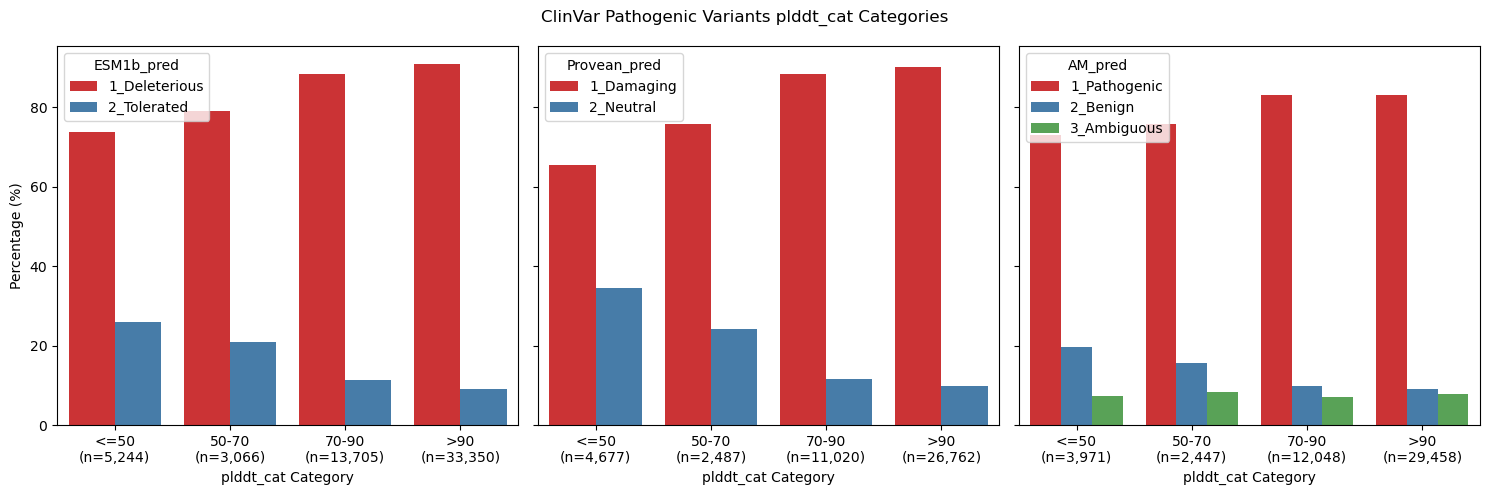

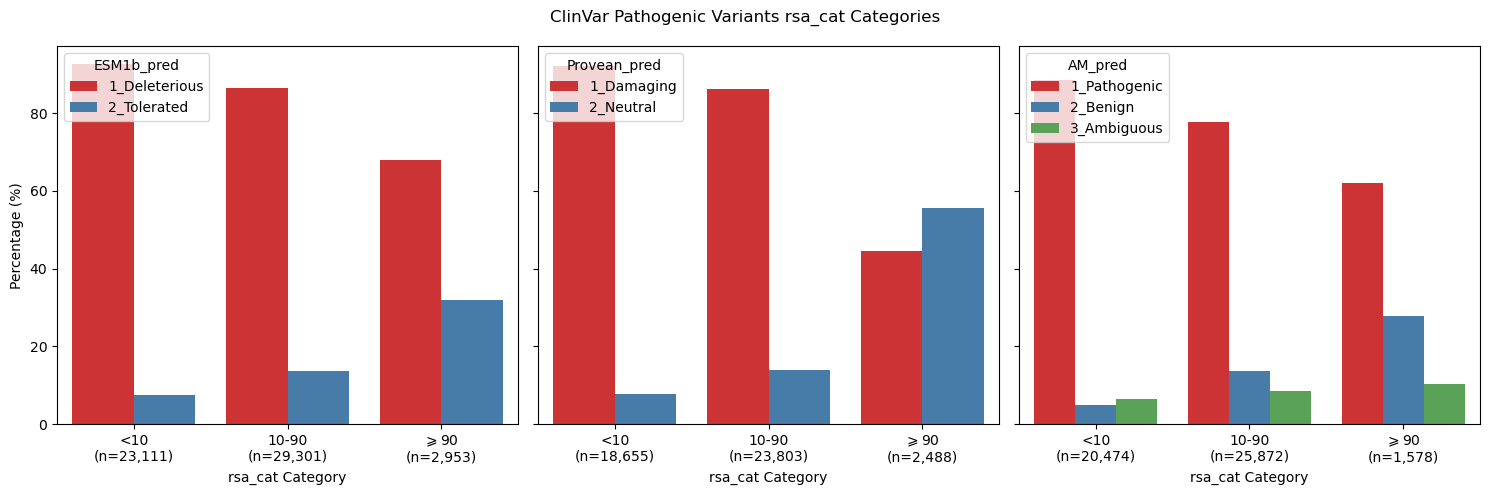

In [15]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# First, calculate the percentages for each group
# Group by both categories and calculate the percentage of each alphamissense_pred within each group

pred_cat = {
    # Make sure the categories are in the right order
    "plddt_cat": ["<=50", "50-70", "70-90", ">90"],
    "rsa_cat": ["<10", "10-90", "$\geqslant$90"]
}
preds = ["ESM1b_pred", "Provean_pred", "AM_pred"]

for cat in ["plddt_cat", "rsa_cat"]:
    fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)
    for pred in preds:
        percentage_df = (
            df_clinvar_w_scores
            .filter((pl.col("clinvar_clnsig_clean")=="1_Pathogenic")&(pl.col(pred)!="."))
            .group_by([cat, pred]) ##"RSA_cat", 
            .agg(count=pl.len())
            .collect()
            .to_pandas()  # Convert to pandas for easier use with seaborn
        )
        # Calculate percentage within each pLDDT_cat and RSA_cat group
        percentage_df['total'] = percentage_df.groupby([cat])['count'].transform('sum') ##, 'RSA_cat'
        percentage_df['percentage'] = percentage_df['count'] / percentage_df['total'] * 100

        # print(percentage_df)
        
        # Filter for just this RSA category
        subset = percentage_df
        
        # Create the stacked barplot
        sns.barplot(
            x=cat, 
            y="percentage", 
            hue=pred,
            hue_order=sorted(percentage_df[pred].unique()),
            data=subset,
            order=pred_cat[cat],
            palette="Set1",  # You can choose a different color palette,
            ax=axes[preds.index(pred)]
        )
        # Get the current x-tick labels
        current_ticks = axes[preds.index(pred)].get_xticks()
        new_labels = []
        # For each category, add the total count to the label
        for category in pred_cat[cat]:
            # Get the total for this category
            total = subset[subset[cat] == category]['total'].iloc[0]
            # Create new label with category and total
            new_label = f"{category}\n(n={total:,})"
            new_labels.append(new_label)

        # Set the new x-tick labels
        # Explicitly set the tick positions and then the labels
        axes[preds.index(pred)].set_xticks(current_ticks[:len(new_labels)])
        axes[preds.index(pred)].set_xticklabels(new_labels)

        axes[preds.index(pred)].set_xlabel(f"{cat} Category")
        axes[preds.index(pred)].set_ylabel("")
        axes[preds.index(pred)].legend(loc="upper left", title=pred)

    axes[0].set_ylabel("Percentage (%)")
    # plt.legend(title="AlphaMissense Prediction")
    plt.suptitle(f"ClinVar Pathogenic Variants {cat} Categories")
    plt.tight_layout()
    plt.show()

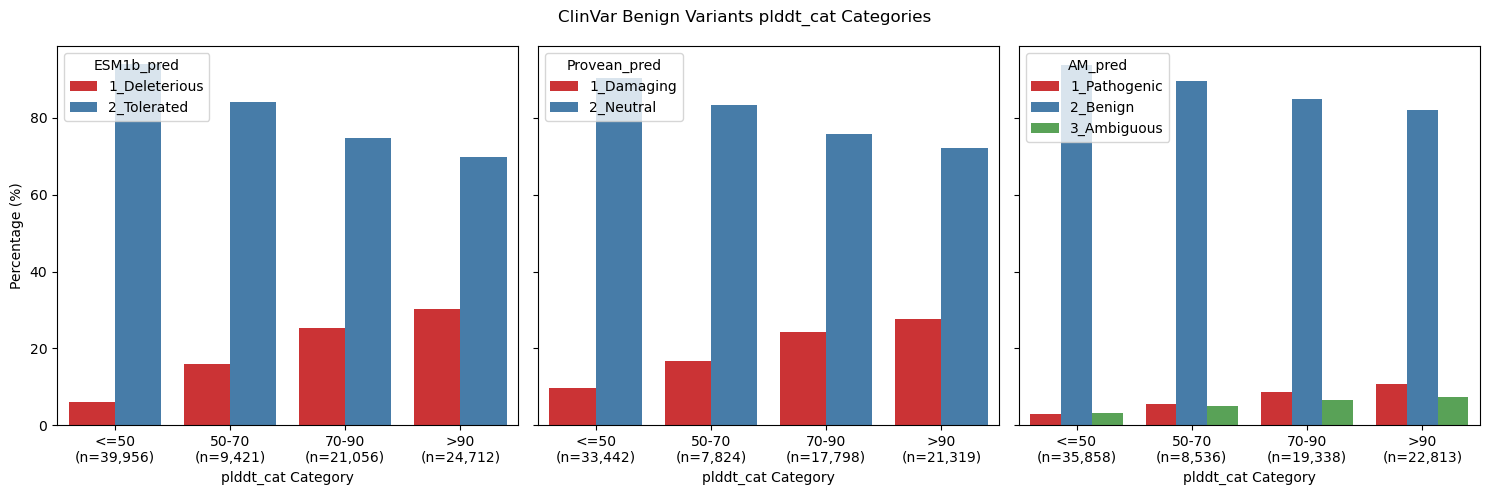

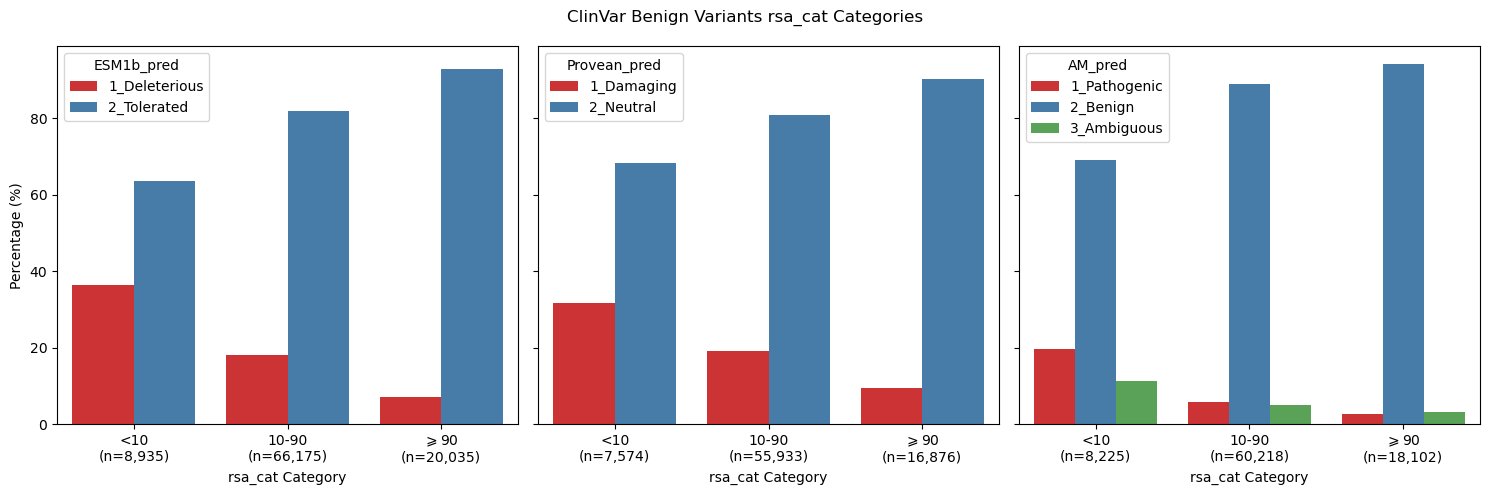

In [16]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# First, calculate the percentages for each group
# Group by both categories and calculate the percentage of each alphamissense_pred within each group

pred_cat = {
    # Make sure the categories are in the right order
    "plddt_cat": ["<=50", "50-70", "70-90", ">90"],
    "rsa_cat": ["<10", "10-90", "$\geqslant$90"]
}
preds = ["ESM1b_pred", "Provean_pred", "AM_pred"]

for cat in ["plddt_cat", "rsa_cat"]:
    fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)
    for pred in preds:
        percentage_df = (
            df_clinvar_w_scores
            .filter((pl.col("clinvar_clnsig_clean")=="2_Benign")&(pl.col(pred)!="."))
            .group_by([cat, pred]) ##"RSA_cat", 
            .agg(count=pl.len())
            .collect()
            .to_pandas()  # Convert to pandas for easier use with seaborn
        )
        # Calculate percentage within each pLDDT_cat and RSA_cat group
        percentage_df['total'] = percentage_df.groupby([cat])['count'].transform('sum') ##, 'RSA_cat'
        percentage_df['percentage'] = percentage_df['count'] / percentage_df['total'] * 100
        
        # Filter for just this RSA category
        subset = percentage_df
        
        # Create the stacked barplot
        sns.barplot(
            x=cat, 
            y="percentage", 
            hue=pred,
            hue_order=sorted(percentage_df[pred].unique()),
            data=subset,
            order=pred_cat[cat],
            palette="Set1",  # You can choose a different color palette,
            ax=axes[preds.index(pred)]
        )
        # Get the current x-tick labels
        current_ticks = axes[preds.index(pred)].get_xticks()
        new_labels = []
        # For each category, add the total count to the label
        for category in pred_cat[cat]:
            # Get the total for this category
            total = subset[subset[cat] == category]['total'].iloc[0]
            # Create new label with category and total
            new_label = f"{category}\n(n={total:,})"
            new_labels.append(new_label)

        # Set the new x-tick labels
        # Explicitly set the tick positions and then the labels
        axes[preds.index(pred)].set_xticks(current_ticks[:len(new_labels)])
        axes[preds.index(pred)].set_xticklabels(new_labels)
        
        axes[preds.index(pred)].set_xlabel(f"{cat} Category")
        axes[preds.index(pred)].set_ylabel("")
        axes[preds.index(pred)].legend(loc="upper left", title=pred)

    axes[0].set_ylabel("Percentage (%)")
    # plt.legend(title="AlphaMissense Prediction")
    plt.suptitle(f"ClinVar Benign Variants {cat} Categories")
    plt.tight_layout()
    plt.show()